Zaimplementuj aplikację szacującą czas ukończenia półmaratonu dla zadanych danych

1. Umieść dane w Digital Ocean Spaces

1. Napisz notebook, który będzie Twoim pipelinem do trenowania modelu
    * czyta dane z Digital Ocean Spaces
    * czyści je
    * trenuje model (dobierz odpowiednie metryki [feature selection])
    * nowa wersja modelu jest zapisywana lokalnie i do Digital Ocean Spaces

1. Aplikacja
    * opakuj model w aplikację streamlit
    * wdróż (deploy) aplikację za pomocą Digital Ocean AppPlatform 
    * wejściem jest pole tekstowe, w którym użytkownik się przedstawia, mówi o tym
    jaka jest jego płeć, wiek i czas na 5km
    * jeśli użytkownik podał za mało danych, wyświetl informację o tym jakich danych brakuje
    * za pomocą LLM (OpenAI) wyłuskaj potrzebne dane, potrzebne dla Twojego modelu
    do określenia, do słownika (dictionary lub JSON)
    * tę część podepnij do Langfuse, aby zbierać metryki o skuteczności działania LLM'a



# Pipeline trenowania modelu – półmaraton Wrocław

Kroki:
1. Konfiguracja i połączenie z Digital Ocean Spaces
2. Umieszczenie surowych danych w Spaces (jednorazowo)
3. Wczytanie danych **ze Spaces**
4. Czyszczenie danych
5. Feature selection
6. Trening i porównanie modeli
7. Zapis nowej wersji modelu lokalnie i do Spaces

## 1. Konfiguracja

In [1]:
import io
import json
import os
from datetime import datetime

import boto3
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv

load_dotenv(".env")

BUCKET_NAME = "arek-polmaraton"
RAW_PREFIX = "data/raw/"
MODELS_PREFIX = "models/"
LOCAL_MODELS_DIR = "models"
RANDOM_STATE = 42

# klucze AWS_ACCESS_KEY_ID, AWS_SECRET_ACCESS_KEY i AWS_ENDPOINT_URL_S3 są w .env
s3 = boto3.client("s3")

## 2. Umieszczenie danych w Digital Ocean Spaces

Wysyłamy pliki CSV tylko wtedy, gdy jeszcze ich nie ma w buckecie.

In [2]:
LOCAL_DATA_FILES = [
    "halfmarathon_wroclaw_2023__final.csv",
    "halfmarathon_wroclaw_2024__final.csv",
]

existing = {obj["Key"] for obj in s3.list_objects_v2(Bucket=BUCKET_NAME, Prefix=RAW_PREFIX).get("Contents", [])}

for file_name in LOCAL_DATA_FILES:
    key = RAW_PREFIX + file_name
    if key in existing:
        print(f"Już jest w Spaces: {key}")
    else:
        s3.upload_file(Filename=file_name, Bucket=BUCKET_NAME, Key=key)
        print(f"Wysłano: {file_name} -> s3://{BUCKET_NAME}/{key}")

Wysłano: halfmarathon_wroclaw_2023__final.csv -> s3://arek-polmaraton/data/raw/halfmarathon_wroclaw_2023__final.csv
Wysłano: halfmarathon_wroclaw_2024__final.csv -> s3://arek-polmaraton/data/raw/halfmarathon_wroclaw_2024__final.csv


## 3. Wczytanie danych z Digital Ocean Spaces

In [3]:
def read_csv_from_spaces(key):
    obj = s3.get_object(Bucket=BUCKET_NAME, Key=key)
    return pd.read_csv(io.BytesIO(obj["Body"].read()), sep=";")


frames = []
for obj in s3.list_objects_v2(Bucket=BUCKET_NAME, Prefix=RAW_PREFIX)["Contents"]:
    key = obj["Key"]
    if not key.endswith(".csv"):
        continue
    df_year = read_csv_from_spaces(key)
    # rok biegu wyciągamy z nazwy pliku, np. halfmarathon_wroclaw_2023__final.csv
    df_year["Rok biegu"] = int(key.split("_")[-3])
    print(f"{key}: {df_year.shape}")
    frames.append(df_year)

df_raw = pd.concat(frames, ignore_index=True)
df_raw.shape

data/raw/halfmarathon_wroclaw_2023__final.csv: (8950, 28)
data/raw/halfmarathon_wroclaw_2024__final.csv: (13007, 28)


(21957, 28)

In [4]:
df_raw.head()

,Miejsce,Numer startowy,Imię,Nazwisko,Miasto,Kraj,Drużyna,Płeć,Płeć Miejsce,Kategoria wiekowa,...,15 km Czas,15 km Miejsce Open,15 km Tempo,20 km Czas,20 km Miejsce Open,20 km Tempo,Tempo Stabilność,Czas,Tempo,Rok biegu
0,1.0,1787,TOMASZ,GRYCKO,NaN,POL,UKS BLIZA WŁADYSŁAWOWO,M,1.0,M30,...,00:44:47,1.0,3.106667,01:01:43,1.0,3.386667,0.031400,01:04:59,3.080509,2023
1,2.0,3,ARKADIUSZ,GARDZIELEWSKI,WROCŁAW,POL,ARKADIUSZGARDZIELEWSKI.PL,M,2.0,M30,...,00:45:26,2.0,3.143333,01:03:08,2.0,3.540000,0.038000,01:06:23,3.146875,2023
2,3.0,3832,KRZYSZTOF,HADAS,POZNAŃ,POL,NaN,M,3.0,M20,...,00:47:34,3.0,3.236667,01:05:09,3.0,3.516667,0.024067,01:08:24,3.242475,2023
3,4.0,416,DAMIAN,DYDUCH,KĘPNO,POL,AZS POLITECHNIKA OPOLSKA,M,4.0,M30,...,00:48:49,5.0,3.330000,01:06:54,4.0,3.616667,0.025467,01:10:16,3.330963,2023
4,5.0,8476,KAMIL,MAŃKOWSKI,MIRKÓW,POL,PARKRUN WROCŁAW,M,5.0,M20,...,00:49:31,7.0,3.386667,01:07:27,5.0,3.586667,0.023000,01:10:27,3.339654,2023


In [5]:
df_raw[["Płeć", "Rocznik", "5 km Czas", "Czas"]].isna().sum()

Płeć           11
Rocznik       485
5 km Czas    3546
Czas         2055
dtype: int64

## 4. Czyszczenie danych

- czasy `hh:mm:ss` → sekundy (`DNS` / `DNF` → brak)
- wiek = rok biegu − rocznik
- usuwamy osoby bez czasu końcowego, bez czasu na 5 km, bez płci lub z nierealnym rocznikiem
- usuwamy ewidentne błędy pomiaru (np. 5 km poniżej 13 minut)

In [6]:
# Snippet pomocniczy - zmiana czasu na sekundy

def convert_time_to_seconds(time):
    if pd.isnull(time) or time in ['DNS', 'DNF']:
        return None
    time = time.split(':')
    return int(time[0]) * 3600 + int(time[1]) * 60 + int(time[2])

In [7]:
df = pd.DataFrame({
    "plec": df_raw["Płeć"],
    "rocznik": df_raw["Rocznik"],
    "rok_biegu": df_raw["Rok biegu"],
    "czas_5km_s": df_raw["5 km Czas"].apply(convert_time_to_seconds),
    "czas_s": df_raw["Czas"].apply(convert_time_to_seconds),
})
df["wiek"] = df["rok_biegu"] - df["rocznik"]

print("Przed czyszczeniem:", len(df))
df = df.dropna(subset=["plec", "rocznik", "czas_5km_s", "czas_s"])
df = df[df["plec"].isin(["M", "K"])]
df = df[df["wiek"].between(15, 90)]
df = df[df["czas_5km_s"].between(13 * 60, 60 * 60)]        # 5 km: 13 – 60 min
df = df[df["czas_s"].between(60 * 60, 4 * 60 * 60)]        # półmaraton: 1 – 4 h
# tempo na mecie nie może być absurdalnie szybsze niż na 5 km (błąd pomiaru)
df = df[(df["czas_s"] / 21.0975) / (df["czas_5km_s"] / 5) > 0.85]
print("Po czyszczeniu:", len(df))

df["plec_m"] = (df["plec"] == "M").astype(int)
df = df.reset_index(drop=True)
df.describe()

Przed czyszczeniem: 21957
Po czyszczeniu: 17900


,rocznik,rok_biegu,czas_5km_s,czas_s,wiek,plec_m
count,17900.000000,17900.000000,17900.000000,17900.000000,17900.000000,17900.000000
mean,1984.376592,2023.558156,1671.909888,7391.414413,39.181564,0.711620
std,10.256459,0.496620,245.043004,1211.087830,10.231899,0.453021
min,1934.000000,2023.000000,877.000000,3843.000000,17.000000,0.000000
25%,1978.000000,2023.000000,1500.000000,6543.000000,32.000000,0.000000
50%,1985.000000,2024.000000,1659.000000,7239.500000,39.000000,1.000000
75%,1992.000000,2024.000000,1833.000000,8127.000000,46.000000,1.000000
max,2006.000000,2024.000000,2960.000000,12512.000000,89.000000,1.000000


## 5. Feature selection

Kandydaci na cechy to to, co użytkownik może podać o sobie w aplikacji: **płeć**, **wiek**, **czas na 5 km** (+ dla porównania rok biegu). Sprawdzamy:
1. korelację z czasem końcowym,
2. mutual information,
3. jak zmienia się błąd modelu (MAE w walidacji krzyżowej) dla różnych podzbiorów cech.

In [8]:
CANDIDATES = ["czas_5km_s", "wiek", "plec_m", "rok_biegu"]
TARGET = "czas_s"

df[CANDIDATES + [TARGET]].corr()[TARGET].sort_values(key=abs, ascending=False)

czas_s        1.000000
czas_5km_s    0.940402
plec_m       -0.314331
wiek          0.066207
rok_biegu     0.039058
Name: czas_s, dtype: float64

In [9]:
from sklearn.feature_selection import mutual_info_regression

mi = mutual_info_regression(df[CANDIDATES], df[TARGET], discrete_features=[False, False, True, True], random_state=RANDOM_STATE)
pd.Series(mi, index=CANDIDATES).sort_values(ascending=False)

czas_5km_s    1.297334
plec_m        0.054997
wiek          0.018660
rok_biegu     0.008487
dtype: float64

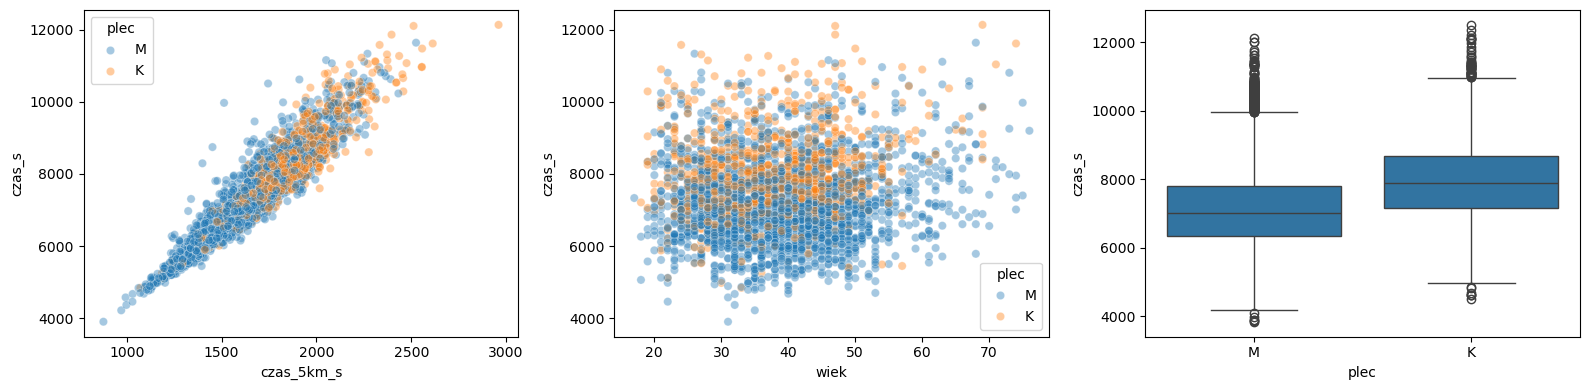

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=df.sample(3000, random_state=RANDOM_STATE), x="czas_5km_s", y="czas_s", hue="plec", alpha=0.4, ax=axes[0])
sns.scatterplot(data=df.sample(3000, random_state=RANDOM_STATE), x="wiek", y="czas_s", hue="plec", alpha=0.4, ax=axes[1])
sns.boxplot(data=df, x="plec", y="czas_s", ax=axes[2])
plt.tight_layout()

In [11]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

feature_sets = {
    "5km": ["czas_5km_s"],
    "5km + płeć": ["czas_5km_s", "plec_m"],
    "5km + wiek": ["czas_5km_s", "wiek"],
    "5km + płeć + wiek": ["czas_5km_s", "plec_m", "wiek"],
    "5km + płeć + wiek + rok": ["czas_5km_s", "plec_m", "wiek", "rok_biegu"],
    "płeć + wiek (bez 5km)": ["plec_m", "wiek"],
}

fs_results = []
for name, cols in feature_sets.items():
    scores = -cross_val_score(HistGradientBoostingRegressor(random_state=RANDOM_STATE), df[cols], df[TARGET],
                              cv=cv, scoring="neg_mean_absolute_error")
    fs_results.append({"cechy": name, "MAE [s]": scores.mean(), "MAE [min]": scores.mean() / 60})

pd.DataFrame(fs_results).sort_values("MAE [s]")

,cechy,MAE [s],MAE [min]
4,5km + płeć + wiek + rok,294.940427,4.915674
2,5km + wiek,300.344532,5.005742
3,5km + płeć + wiek,300.428321,5.007139
0,5km,301.279339,5.021322
1,5km + płeć,301.573850,5.026231
5,płeć + wiek (bez 5km),889.344933,14.822416


**Wnioski z feature selection:**
- **Czas na 5 km** dominuje: korelacja z czasem końcowym ≈ 0.94, najwyższe mutual information, a bez niego MAE rośnie z ok. 5 do ok. 15 minut.
- **Płeć** i **wiek** same w sobie są powiązane z wynikiem (płeć: korelacja ≈ -0.31), ale gdy znamy już czas na 5 km, poprawiają MAE tylko symbolicznie – większość tej informacji „siedzi” już w tempie na 5 km.
- **Rok biegu** daje niewielką poprawę (warunki danego biegu), ale dla przyszłego biegu nie jest znany i użytkownik go nie poda – odrzucamy.

➡️ Finalne cechy: **`czas_5km_s`, `plec_m`, `wiek`**. Płeć i wiek zostawiamy, bo nie pogarszają modelu, są tanie do zebrania (aplikacja i tak o nie pyta) i pozwalają modelowi rozróżnić osoby z tym samym czasem na 5 km.

## 6. Trening i porównanie modeli

Metryki: **MAE** (średni błąd w sekundach – najłatwiejszy do interpretacji), **RMSE** i **R²**.

In [12]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FEATURES = ["czas_5km_s", "plec_m", "wiek"]

X_train, X_test, y_train, y_test = train_test_split(df[FEATURES], df[TARGET], test_size=0.2, random_state=RANDOM_STATE)

models = {
    "LinearRegression": make_pipeline(StandardScaler(), LinearRegression()),
    "RandomForest": RandomForestRegressor(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}

results = []
for name, model in models.items():
    cv_mae = -cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error").mean()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "model": name,
        "CV MAE [s]": cv_mae,
        "test MAE [s]": mean_absolute_error(y_test, pred),
        "test RMSE [s]": mean_squared_error(y_test, pred) ** 0.5,
        "test R2": r2_score(y_test, pred),
    })

results_df = pd.DataFrame(results).sort_values("CV MAE [s]").reset_index(drop=True)
results_df

,model,CV MAE [s],test MAE [s],test RMSE [s],test R2
0,LinearRegression,299.718999,303.740979,414.155037,0.883656
1,HistGradientBoosting,301.145305,302.163215,413.700884,0.883911
2,RandomForest,302.059224,304.097120,415.930349,0.882657


Najlepszy model: LinearRegression
Średni błąd na zbiorze testowym: 5.1 min


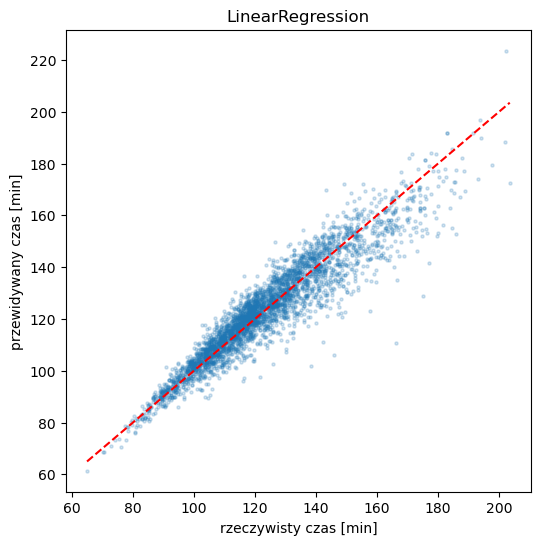

In [13]:
best_name = results_df.loc[0, "model"]
best_model = models[best_name]
best_metrics = results_df.loc[0].drop("model").to_dict()
print(f"Najlepszy model: {best_name}")
print(f"Średni błąd na zbiorze testowym: {best_metrics['test MAE [s]'] / 60:.1f} min")

pred = best_model.predict(X_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test / 60, pred / 60, alpha=0.2, s=5)
lims = [y_test.min() / 60, y_test.max() / 60]
plt.plot(lims, lims, "r--")
plt.xlabel("rzeczywisty czas [min]")
plt.ylabel("przewidywany czas [min]")
plt.title(best_name);

Finalny model trenujemy na **wszystkich** oczyszczonych danych.

In [14]:
final_model = models[best_name]
final_model.fit(df[FEATURES], df[TARGET])

# szybki test sensowności: mężczyzna, 35 lat, 5 km w 25 minut
example = pd.DataFrame([{"czas_5km_s": 25 * 60, "plec_m": 1, "wiek": 35}])
seconds = final_model.predict(example)[0]
print(f"Przykładowa predykcja: {int(seconds // 3600)}:{int(seconds % 3600 // 60):02d}:{int(seconds % 60):02d}")

Przykładowa predykcja: 1:49:49


## 7. Zapis nowej wersji modelu – lokalnie i do Digital Ocean Spaces

Każde uruchomienie pipeline'u tworzy nową wersję (`halfmarathon_model_<data_czas>.pkl`). Dodatkowo nadpisujemy `latest.pkl` – z niego korzysta aplikacja.

In [15]:
version = datetime.now().strftime("%Y%m%d_%H%M%S")
os.makedirs(LOCAL_MODELS_DIR, exist_ok=True)

model_file = f"halfmarathon_model_{version}.pkl"
meta_file = f"halfmarathon_model_{version}.json"

metadata = {
    "version": version,
    "model": best_name,
    "features": FEATURES,
    "target": TARGET,
    "n_rows": len(df),
    "metrics": {k: float(v) for k, v in best_metrics.items()},
}

local_model_path = os.path.join(LOCAL_MODELS_DIR, model_file)
local_meta_path = os.path.join(LOCAL_MODELS_DIR, meta_file)
joblib.dump(final_model, local_model_path)
with open(local_meta_path, "w") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)
print("Zapisano lokalnie:", local_model_path)

for local_path, remote_name in [
    (local_model_path, model_file),
    (local_meta_path, meta_file),
    (local_model_path, "latest.pkl"),
    (local_meta_path, "latest.json"),
]:
    s3.upload_file(Filename=local_path, Bucket=BUCKET_NAME, Key=MODELS_PREFIX + remote_name)
    print(f"Wysłano do Spaces: s3://{BUCKET_NAME}/{MODELS_PREFIX}{remote_name}")

Zapisano lokalnie: models/halfmarathon_model_20261013_232116.pkl
Wysłano do Spaces: s3://arek-polmaraton/models/halfmarathon_model_20261013_232116.pkl
Wysłano do Spaces: s3://arek-polmaraton/models/halfmarathon_model_20261013_232116.json
Wysłano do Spaces: s3://arek-polmaraton/models/latest.pkl
Wysłano do Spaces: s3://arek-polmaraton/models/latest.json


In [16]:
# Wersje modelu w Spaces
for obj in s3.list_objects_v2(Bucket=BUCKET_NAME, Prefix=MODELS_PREFIX)["Contents"]:
    print(obj["Key"], obj["LastModified"])

models/halfmarathon_model_20261013_232116.json 2026-10-13 21:21:17.034000+00:00
models/halfmarathon_model_20261013_232116.pkl 2026-10-13 21:21:16.957000+00:00
models/latest.json 2026-10-13 21:21:17.184000+00:00
models/latest.pkl 2026-10-13 21:21:17.109000+00:00
